# Assignment Number 16

In [18]:
import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt

In [2]:
conn = sql.connect("chinook.db")

def sql_query(q):
    return pd.read_sql_query(q, conn)
    

In [3]:
 sql_query("select * from sqlite_master")

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

In [4]:
sql_query('''SELECT
    g.Name AS Genre,
    COUNT(t.Track_Id) AS Total_Tracks
FROM genre g
JOIN track t
    ON g.genre_Id = t.genre_Id
GROUP BY g.Name
ORDER BY Total_Tracks DESC
LIMIT 10''')

,Genre,Total_Tracks
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


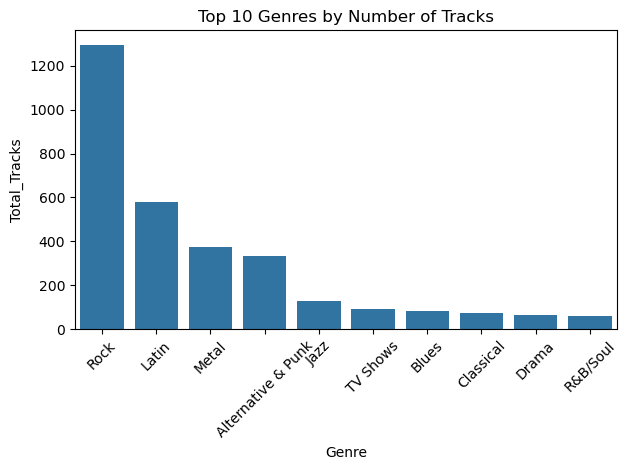

In [22]:
import seaborn as sns

df = sql_query("""
SELECT g.Name AS Genre, COUNT(t.Track_Id) AS Total_Tracks
FROM genre g
JOIN track t ON g.genre_Id = t.genre_Id
GROUP BY g.Name
ORDER BY Total_Tracks DESC
LIMIT 10
""")

sns.barplot(data=df, x="Genre", y="Total_Tracks")
plt.xticks(rotation=45)
plt.title("Top 10 Genres by Number of Tracks")
plt.tight_layout()
plt.show()

## Q3. Write a query to find the top 10 customers who spent the most money.

In [5]:
sql_query('''SELECT
    c.first_Name || ' ' || c.last_Name AS Customer_Name,
    SUM(i.Total) AS Total_Spent
FROM customer c
JOIN invoice  i
    ON c.customer_id = i.customer_id
GROUP BY c.customer_Id, c.first_name, c.last_name
ORDER BY Total_Spent DESC
LIMIT 10''')

,Customer_Name,Total_Spent
0,František Wichterlová,144.54
1,Helena Holý,128.70
2,Hugh O'Reilly,114.84
3,Manoj Pareek,111.87
4,Luís Gonçalves,108.90
5,Fernanda Ramos,106.92
6,João Fernandes,102.96
7,François Tremblay,99.99
8,Wyatt Girard,99.99
9,Jack Smith,98.01


## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [6]:
sql_query('''SELECT
    a.Title AS Album,
    COUNT(t.Track_Id) AS Total_Tracks
FROM album a
JOIN track t
    ON a.Album_Id = t.Album_Id
GROUP BY a.Album_Id, a.Title
ORDER BY Total_Tracks DESC
LIMIT 10''')

,Album,Total_Tracks
0,Greatest Hits,57
1,Minha Historia,34
2,Unplugged,30
3,"Lost, Season 3",26
4,"Lost, Season 1",25
5,"The Office, Season 3",25
6,My Way: The Best Of Frank Sinatra [Disc 1],24
7,"Lost, Season 2",24
8,"Battlestar Galactica (Classic), Season 1",24
9,Afrociberdelia,23


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [7]:
sql_query(
'''SELECT
    ar.name AS artist_name,
    SUM(il.unit_price * il.quantity) AS total_revenue
FROM artist ar
JOIN album al
    ON ar.artist_id = al.artist_id
JOIN track t
    ON al.album_id = t.album_id
JOIN invoice_line il
    ON t.track_id = il.track_id
GROUP BY ar.artist_id, ar.name
ORDER BY total_revenue DESC
LIMIT 5'''
)

,artist_name,total_revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Nirvana,128.70
3,Red Hot Chili Peppers,128.70
4,Pearl Jam,127.71


## Q5. Countries by Average Revenue per Invoice

In [8]:
sql_query('''
SELECT
    billing_country AS Country,
    AVG(total) AS Average_Revenue
FROM invoice
GROUP BY billing_country
ORDER BY Average_Revenue DESC;
''')

,Country,Average_Revenue
0,Czech Republic,9.108000
1,Spain,8.910000
2,Ireland,8.833846
3,United Kingdom,8.768571
4,India,8.721429
5,Belgium,8.627143
6,Germany,8.161463
7,Australia,8.118000
8,Norway,8.030000
9,USA,7.942672


## Q6. Write a query to find the media type with number of tracks.


In [10]:
sql_query('''SELECT
    m.Name AS Media_Type,
    COUNT(t.Track_Id) AS Total_Tracks
FROM media_type m
JOIN track t 
ON m.Media_Type_Id = t.Media_Type_Id
GROUP BY m.Media_Type_Id, m.Name
ORDER BY Total_Tracks DESC
''')

,Media_Type,Total_Tracks
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [11]:

sql_query('''SELECT
    ar.Name AS Artist,
    COUNT(DISTINCT t.Genre_Id) AS Genre_Count
FROM artist ar
JOIN album al ON ar.Artist_Id = al.Artist_Id
JOIN track t ON al.Album_Id = t.Album_Id
GROUP BY ar.Artist_Id, ar.Name
HAVING COUNT(DISTINCT t.Genre_Id) > 1
ORDER BY Genre_Count DESC, Artist
''')

,Artist,Genre_Count
0,Iron Maiden,4
1,Audioslave,3
2,Battlestar Galactica,3
3,Gilberto Gil,3
4,Jamiroquai,3
5,Lenny Kravitz,3
6,Various Artists,3
7,Amy Winehouse,2
8,Antônio Carlos Jobim,2
9,Eric Clapton,2


## Q8. Write a query to list the top 10 longest tracks by duration.

In [12]:

sql_query('''SELECT
    Name AS Track,
    Milliseconds,
    ROUND(Milliseconds / 60000.0, 2) AS Duration_Minutes
FROM track
ORDER BY Milliseconds DESC
LIMIT 10''')


,Track,milliseconds,Duration_Minutes
0,Occupation / Precipice,5286953,88.12
1,Through a Looking Glass,5088838,84.81
2,"Greetings from Earth, Pt. 1",2960293,49.34
3,The Man With Nine Lives,2956998,49.28
4,"Battlestar Galactica, Pt. 2",2956081,49.27
5,"Battlestar Galactica, Pt. 1",2952702,49.21
6,Murder On the Rising Star,2935894,48.93
7,"Battlestar Galactica, Pt. 3",2927802,48.80
8,Take the Celestra,2927677,48.79
9,Fire In Space,2926593,48.78


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

In [13]:

sql_query('''WITH artist_revenue AS (
    SELECT
        ar.Artist_Id,
        ar.Name AS Artist,
        SUM(il.Unit_Price * il.Quantity) AS Revenue
    FROM artist ar
    JOIN album al ON ar.Artist_Id = al.Artist_Id
    JOIN track t ON al.Album_Id = t.Album_Id
    JOIN invoice_line il ON t.Track_Id = il.Track_Id
    GROUP BY ar.Artist_Id, ar.Name
),
top5 AS (
    SELECT *
    FROM artist_revenue
    ORDER BY Revenue DESC
    LIMIT 5
)
SELECT
    Artist,
    Revenue,
    ROUND(
        100.0 * Revenue / (SELECT SUM(Revenue) FROM artist_revenue),
        2
    ) AS Revenue_Share_Percent
FROM top5
ORDER BY Revenue DESC''')


,Artist,Revenue,Revenue_Share_Percent
0,Queen,190.08,4.04
1,Jimi Hendrix,185.13,3.93
2,Nirvana,128.70,2.73
3,Red Hot Chili Peppers,128.70,2.73
4,Pearl Jam,127.71,2.71


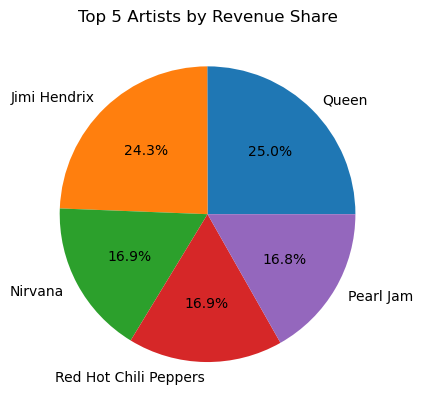

In [19]:
df = sql_query("""
WITH artist_revenue AS (
    SELECT ar.Artist_Id, ar.Name AS Artist,
           SUM(il.Unit_Price * il.Quantity) AS Revenue
    FROM artist ar
    JOIN album al ON ar.Artist_Id = al.Artist_Id
    JOIN track t ON al.Album_Id = t.Album_Id
    JOIN invoice_line il ON t.Track_Id = il.Track_Id
    GROUP BY ar.Artist_Id, ar.Name
),
top5 AS (
    SELECT * FROM artist_revenue
    ORDER BY Revenue DESC LIMIT 5
)
SELECT Artist, Revenue,
       ROUND(100.0 * Revenue /
       (SELECT SUM(Revenue) FROM artist_revenue), 2)
       AS Revenue_Share_Percent
FROM top5
ORDER BY Revenue DESC
""")

plt.pie(
    df["Revenue_Share_Percent"],
    labels=df["Artist"],
    autopct="%1.1f%%"
)
plt.title("Top 5 Artists by Revenue Share")
plt.show()

## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

In [14]:

sql_query('''SELECT
    i.Billing_Country AS Country,
    g.Name AS Genre,
    SUM(il.Unit_Price * il.Quantity) AS Revenue
FROM invoice_line il
JOIN invoice i ON il.Invoice_Id = i.Invoice_Id
JOIN track t ON il.Track_Id = t.Track_Id
JOIN genre g ON t.Genre_Id = g.Genre_Id
WHERE g.Name IN ('Rock', 'Latin', 'Metal')
GROUP BY i.Billing_Country, g.Name
ORDER BY i.Billing_Country, g.Name;
''')

,Country,Genre,Revenue
0,Argentina,Latin,1.98
1,Argentina,Metal,1.98
2,Argentina,Rock,10.89
3,Australia,Latin,1.98
4,Australia,Metal,13.86
...,...,...,...
65,USA,Metal,122.76
66,USA,Rock,555.39
67,United Kingdom,Latin,6.93
68,United Kingdom,Metal,30.69


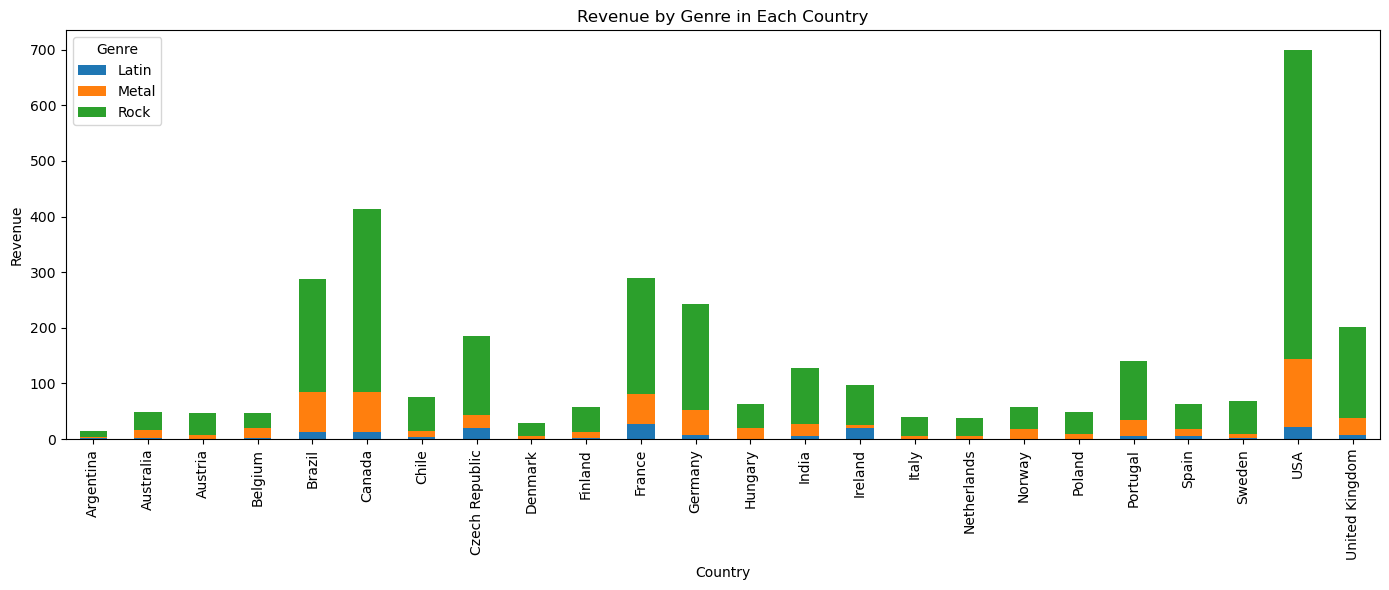

In [20]:
df = sql_query("""
SELECT i.Billing_Country AS Country,
       g.Name AS Genre,
       SUM(il.Unit_Price * il.Quantity) AS Revenue
FROM invoice_line il
JOIN invoice i ON il.Invoice_Id = i.Invoice_Id
JOIN track t ON il.Track_Id = t.Track_Id
JOIN genre g ON t.Genre_Id = g.Genre_Id
WHERE g.Name IN ('Rock', 'Latin', 'Metal')
GROUP BY i.Billing_Country, g.Name
ORDER BY i.Billing_Country, g.Name
""")

pivot_df = df.pivot(
    index="Country",
    columns="Genre",
    values="Revenue"
).fillna(0)

pivot_df.plot(kind="bar", stacked=True, figsize=(14, 6))

plt.title("Revenue by Genre in Each Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()